## LeafShift - Data Exploration and Quality Audit

### 1. Install and import packages

In [1]:
%pip install -q pandas numpy matplotlib Pillow ImageHash tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import hashlib
import json
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm
import imagehash
from IPython.display import display

ImageFile.LOAD_TRUNCATED_IMAGES = False
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

print("Packages imported successfully.")

Packages imported successfully.


### 2. Project paths and analysis settings

In [3]:
# Detect project root whether this notebook is run from the project root or notebooks/.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

PLANTVILLAGE_CONTAINER = PROJECT_ROOT / "data" / "raw" / "plantvillage"
PLANTDOC_CONTAINER = PROJECT_ROOT / "data" / "raw" / "plantdoc"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
RANDOM_SEED = 42
PHASH_DISTANCE_THRESHOLD = 4  # Candidate threshold only; manually inspect the matches.
PHASH_MAX_IMAGES = None       # None = scan all PlantVillage images. Set e.g. 5000 for a quick test.

# Official emmarex/plantdisease content: 15 class folders, 20,638 images.
EXPECTED_PLANTVILLAGE_IMAGES = 20_638


def find_class_root(container: Path, dataset_name: str) -> Path:
    """Return the folder that directly holds the class folders.
    """
    if not container.exists():
        return container

    root = container
    while True:
        visible_dirs = [p for p in root.iterdir() if p.is_dir() and not p.name.startswith(".")]
        has_direct_images = any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS for p in root.iterdir()
        )
        if has_direct_images or len(visible_dirs) != 1:
            return root
        if visible_dirs[0].name.lower() != dataset_name.lower():
            return root
        root = visible_dirs[0]


PLANTVILLAGE_DIR = find_class_root(PLANTVILLAGE_CONTAINER, "PlantVillage")
PLANTDOC_DIR = find_class_root(PLANTDOC_CONTAINER, "plantdoc")

print("Project root:            ", PROJECT_ROOT)
print("PlantVillage container:  ", PLANTVILLAGE_CONTAINER, "| exists:", PLANTVILLAGE_CONTAINER.exists())
print("PlantVillage class root: ", PLANTVILLAGE_DIR, "| exists:", PLANTVILLAGE_DIR.exists())
print("PlantVillage container:  ", PLANTDOC_CONTAINER, "| exists:", PLANTDOC_CONTAINER.exists())
print("PlantDoc class root:     ", PLANTDOC_DIR, "| exists:", PLANTDOC_DIR.exists())
if PLANTVILLAGE_DIR != PLANTVILLAGE_CONTAINER:
    print("\nNote: the download left a nested folder. The class root above is the one used.")


Project root:             C:\Users\eminha\Documents\Projects\AAI\LeafShift
PlantVillage container:   C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\raw\plantvillage | exists: True
PlantVillage class root:  C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\raw\plantvillage\PlantVillage | exists: True
PlantVillage container:   C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\raw\plantdoc | exists: True
PlantDoc class root:      C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\raw\plantdoc | exists: True

Note: the download left a nested folder. The class root above is the one used.


### 3. Define the shared 9-class mapping

In [4]:
CLASS_MAPPING = {
    "Potato - early blight": {
        "plantvillage": ["Potato___Early_blight"],
        "plantdoc": ["Potato leaf early blight"],
    },
    "Potato - late blight": {
        "plantvillage": ["Potato___Late_blight"],
        "plantdoc": ["Potato leaf late blight"],
    },
    "Tomato - bacterial spot": {
        "plantvillage": ["Tomato___Bacterial_spot"],
        "plantdoc": ["Tomato leaf bacterial spot", "Tomato bacterial spot leaf"],
    },
    "Tomato - early blight": {
        "plantvillage": ["Tomato___Early_blight"],
        "plantdoc": ["Tomato Early blight leaf", "Tomato early blight leaf"],
    },
    "Tomato - late blight": {
        "plantvillage": ["Tomato___Late_blight"],
        "plantdoc": ["Tomato leaf late blight", "Tomato late blight leaf"],
    },
    "Tomato - leaf mold": {
        "plantvillage": ["Tomato___Leaf_Mold"],
        "plantdoc": ["Tomato mold leaf", "Tomato leaf mold"],
    },
    "Tomato - septoria leaf spot": {
        "plantvillage": ["Tomato___Septoria_leaf_spot"],
        "plantdoc": ["Tomato Septoria leaf spot", "Tomato leaf septoria spot"],
    },
    "Tomato - spider mites": {
        "plantvillage": ["Tomato___Spider_mites Two-spotted_spider_mite"],
        "plantdoc": ["Tomato two spotted spider mites leaf", "Tomato spider mites leaf"],
    },
    "Tomato - healthy": {
        "plantvillage": ["Tomato___healthy"],
        "plantdoc": ["Tomato leaf", "Tomato healthy", "Tomato healthy leaf"],
    },
}

assert len(CLASS_MAPPING) == 9, "The shared mapping holds 9 classes: Potato - healthy has no PlantDoc counterpart."
print(f"Configured {len(CLASS_MAPPING)} shared classes (Potato - healthy is excluded: no PlantDoc class).")

Configured 9 shared classes (Potato - healthy is excluded: no PlantDoc class).


### 4. Find images and inspect the actual folder labels

In [5]:
def collect_images(root: Path, dataset_name: str, skip_repeated_name_trees: bool = True) -> pd.DataFrame:
    """Return one row per image. The immediate parent folder is treated as its class label.
    """
    columns = ["dataset", "path", "relative_path", "folder_label", "extension"]
    if not root.exists():
        return pd.DataFrame(columns=columns)

    root = root.resolve()
    rows = []
    ignored = 0
    for path in sorted(root.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        relative = path.relative_to(root)
        if skip_repeated_name_trees:
            folder_parts = [part.lower() for part in relative.parts[:-1]]
            if len(folder_parts) != len(set(folder_parts)):
                ignored += 1
                continue
        rows.append({
            "dataset": dataset_name,
            "path": str(path),
            "relative_path": str(relative).replace("\\", "/"),
            "folder_label": path.parent.name,
            "extension": path.suffix.lower(),
        })

    frame = pd.DataFrame(rows, columns=columns)
    message = f"{dataset_name}: {len(frame):,} images kept"
    if ignored:
        message += f", {ignored:,} ignored from a repeated-name duplicate tree"
    print(message)
    return frame


pv_df = collect_images(PLANTVILLAGE_DIR, "PlantVillage")
pd_df = collect_images(PLANTDOC_DIR, "PlantDoc")

print(f"\nPlantVillage images found: {len(pv_df):,}")
print(f"PlantDoc images found:     {len(pd_df):,}")

if pv_df.empty or pd_df.empty:
    print("\nAt least one dataset folder is empty or not found.")
    print("Check the folder paths in Section 2, extract the datasets, and rerun this section.")
else:
    print("\nBoth datasets were found.")

if not pv_df.empty:
    print(f"Distinct PlantVillage class folders: {pv_df['folder_label'].nunique()}")
    file_names = pd.DataFrame({
        "folder_label": pv_df["folder_label"],
        "file_name": pv_df["path"].map(lambda value: Path(value).name),
    })
    repeated_names = int(file_names.duplicated().sum())
    if repeated_names:
        print(f"WARNING: {repeated_names:,} images share a class and file name. "
              "A duplicate copy is probably still visible to the scan.")
    if abs(len(pv_df) - EXPECTED_PLANTVILLAGE_IMAGES) > 50:
        print(f"WARNING: expected about {EXPECTED_PLANTVILLAGE_IMAGES:,} images, "
              f"found {len(pv_df):,}. Check the download.")
    else:
        print(f"Image count matches the official dataset ({EXPECTED_PLANTVILLAGE_IMAGES:,}).")


PlantVillage: 20,638 images kept


PlantDoc: 2,922 images kept

PlantVillage images found: 20,638
PlantDoc images found:     2,922

Both datasets were found.
Distinct PlantVillage class folders: 15
Image count matches the official dataset (20,638).


In [6]:
def show_folder_labels(df: pd.DataFrame, title: str):
    if df.empty:
        print(f"{title}: no images found")
        return
    labels = sorted(df["folder_label"].dropna().unique().tolist())
    print(f"{title} - {len(labels)} folder labels")
    for label in labels:
        print(" •", label)

show_folder_labels(pv_df, "PlantVillage")
print()
show_folder_labels(pd_df, "PlantDoc")

PlantVillage - 15 folder labels
 • Pepper__bell___Bacterial_spot
 • Pepper__bell___healthy
 • Potato___Early_blight
 • Potato___Late_blight
 • Potato___healthy
 • Tomato_Bacterial_spot
 • Tomato_Early_blight
 • Tomato_Late_blight
 • Tomato_Leaf_Mold
 • Tomato_Septoria_leaf_spot
 • Tomato_Spider_mites_Two_spotted_spider_mite
 • Tomato__Target_Spot
 • Tomato__Tomato_YellowLeaf__Curl_Virus
 • Tomato__Tomato_mosaic_virus
 • Tomato_healthy

PlantDoc - 28 folder labels
 • Apple_Scab_Leaf
 • Apple_leaf
 • Apple_rust_leaf
 • Bell_pepper_leaf
 • Bell_pepper_leaf_spot
 • Blueberry_leaf
 • Cherry_leaf
 • Corn_Gray_leaf_spot
 • Corn_leaf_blight
 • Corn_rust_leaf
 • Peach_leaf
 • Potato_leaf_early_blight
 • Potato_leaf_late_blight
 • Raspberry_leaf
 • Soyabean_leaf
 • Squash_Powdery_mildew_leaf
 • Strawberry_leaf
 • Tomato_Early_blight_leaf
 • Tomato_Septoria_leaf_spot
 • Tomato_leaf
 • Tomato_leaf_bacterial_spot
 • Tomato_leaf_late_blight
 • Tomato_leaf_mosaic_virus
 • Tomato_leaf_yellow_virus
 • 

### 5. Raw image counts and class imbalance

In [7]:
def class_count_table(df: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame(columns=["dataset", "folder_label", "image_count", "share_percent"])
    counts = df.groupby("folder_label").size().sort_values(ascending=False)
    return pd.DataFrame({
        "dataset": dataset_name,
        "folder_label": counts.index,
        "image_count": counts.values,
        "share_percent": (counts.values / counts.sum() * 100).round(2),
    })

pv_raw_counts = class_count_table(pv_df, "PlantVillage")
pd_raw_counts = class_count_table(pd_df, "PlantDoc")
raw_counts = pd.concat([pv_raw_counts, pd_raw_counts], ignore_index=True)
display(raw_counts)

if not raw_counts.empty:
    raw_counts.to_csv(PROCESSED_DIR / "raw_class_counts.csv", index=False)
    print("Saved:", PROCESSED_DIR / "raw_class_counts.csv")

,dataset,folder_label,image_count,share_percent
0,PlantVillage,Tomato__Tomato_YellowLeaf__Curl_Virus,3208,15.54
1,PlantVillage,Tomato_Bacterial_spot,2127,10.31
2,PlantVillage,Tomato_Late_blight,1909,9.25
3,PlantVillage,Tomato_Septoria_leaf_spot,1771,8.58
4,PlantVillage,Tomato_Spider_mites_Two_spotted_spider_mite,1676,8.12
5,PlantVillage,Tomato_healthy,1591,7.71
6,PlantVillage,Pepper__bell___healthy,1478,7.16
7,PlantVillage,Tomato__Target_Spot,1404,6.80
8,PlantVillage,Potato___Early_blight,1000,4.85
9,PlantVillage,Potato___Late_blight,1000,4.85


Saved: C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\processed\raw_class_counts.csv


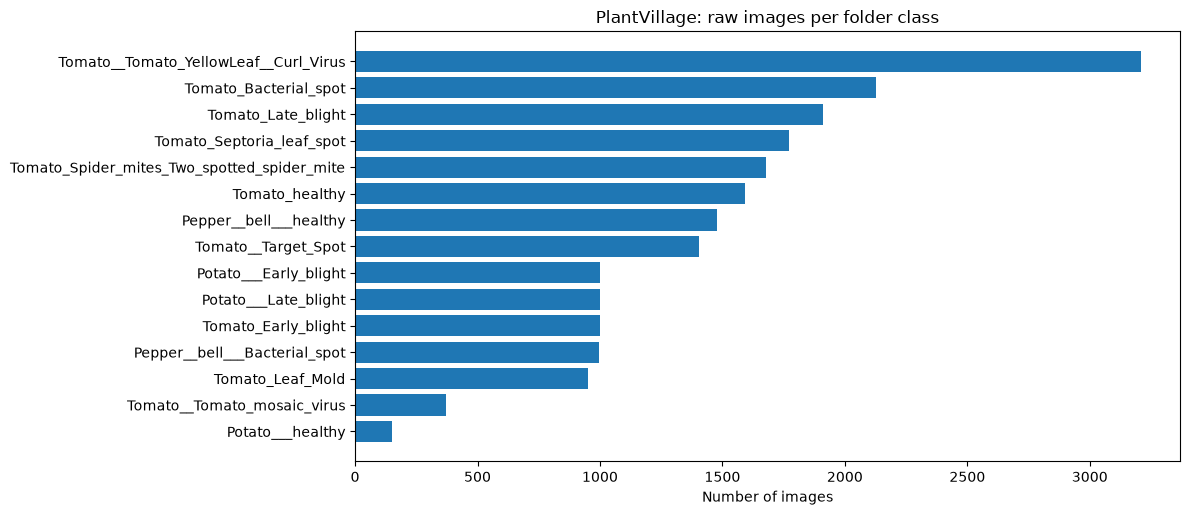

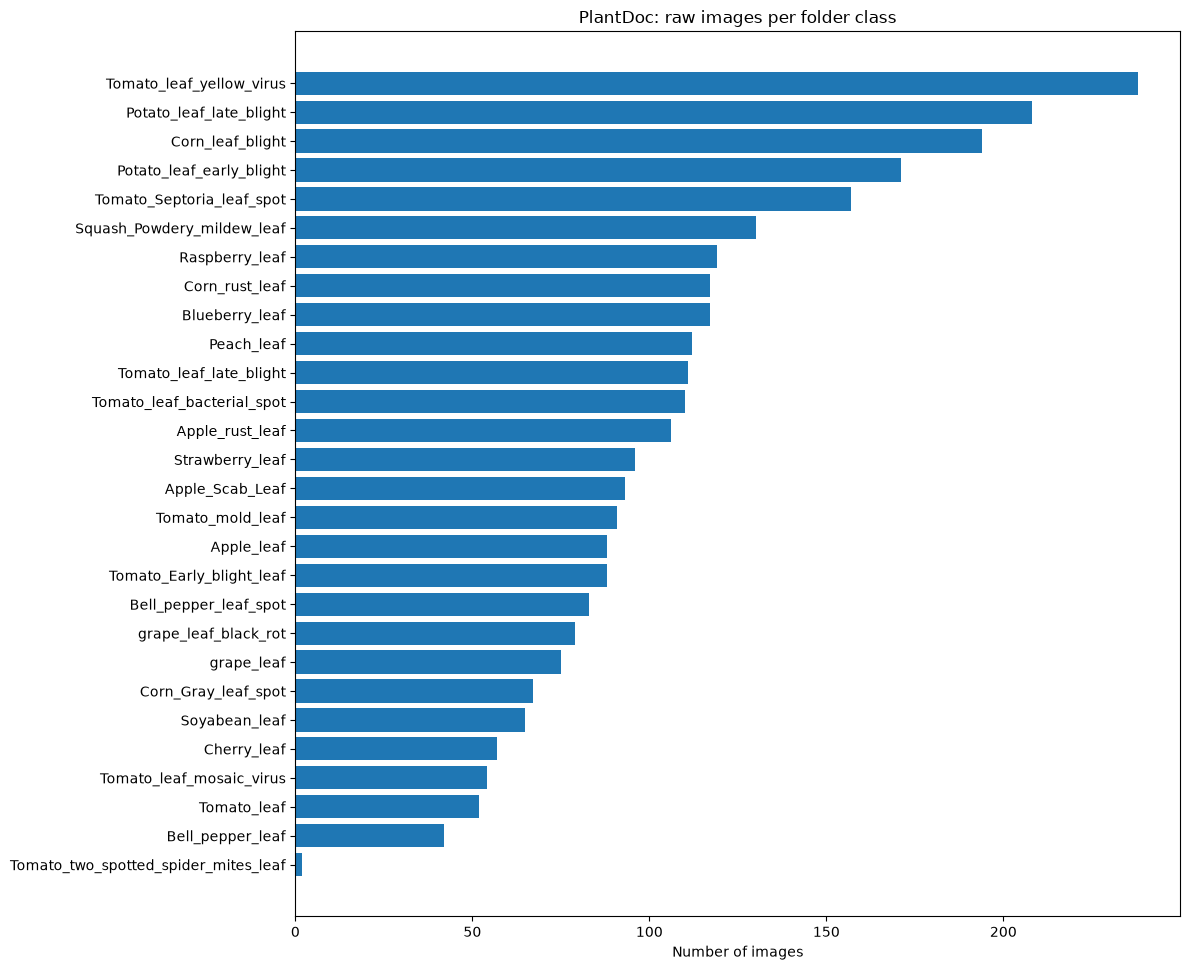

In [8]:
for dataset_name, count_table in [("PlantVillage", pv_raw_counts), ("PlantDoc", pd_raw_counts)]:
    if count_table.empty:
        continue
    plt.figure(figsize=(12, max(4, 0.35 * len(count_table))))
    plt.barh(count_table["folder_label"], count_table["image_count"])
    plt.gca().invert_yaxis()
    plt.title(f"{dataset_name}: raw images per folder class")
    plt.xlabel("Number of images")
    plt.tight_layout()
    plt.show()

### 6. Check image readability and image dimensions

In [9]:
def inspect_image(path_string: str) -> dict:
    try:
        with Image.open(path_string) as image:
            image.verify()
        with Image.open(path_string) as image:
            width, height = image.size
            mode = image.mode
        return {"readable": True, "width": width, "height": height, "mode": mode, "error": ""}
    except Exception as exc:
        return {"readable": False, "width": np.nan, "height": np.nan, "mode": "", "error": str(exc)[:250]}

# This checks every image. It can take a little time for large datasets.
all_images = pd.concat([pv_df, pd_df], ignore_index=True)
quality_records = []
for row in tqdm(all_images.itertuples(index=False), total=len(all_images), desc="Checking images"):
    result = inspect_image(row.path)
    quality_records.append({
        "dataset": row.dataset,
        "relative_path": row.relative_path,
        "folder_label": row.folder_label,
        **result,
    })

quality_df = pd.DataFrame(quality_records)
quality_df.to_csv(PROCESSED_DIR / "image_quality_report.csv", index=False)
display(quality_df.groupby(["dataset", "readable"]).size().rename("image_count").reset_index())
print("Saved:", PROCESSED_DIR / "image_quality_report.csv")

Checking images:   0%|          | 0/23560 [00:00<?, ?it/s]

,dataset,readable,image_count
0,PlantDoc,True,2922
1,PlantVillage,True,20638


Saved: C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\processed\image_quality_report.csv


width                                                     \
                count   mean    std    min    25%    50%     75%     max   
dataset                                                                    
PlantDoc       2922.0  911.9  786.6  115.0  400.2  640.0  1155.8  6000.0   
PlantVillage  20638.0  256.0    0.0  256.0  256.0  256.0   256.0   256.0   

               height                                                     
                count   mean    std    min    25%    50%     75%     max  
dataset                                                                   
PlantDoc       2922.0  800.5  679.0   69.0  350.0  560.5  1024.0  6000.0  
PlantVillage  20638.0  256.0    0.0  256.0  256.0  256.0   256.0   256.0

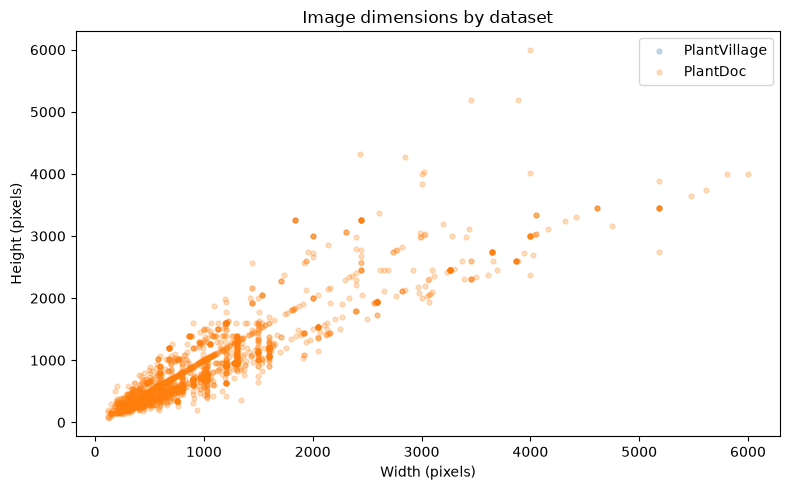

In [10]:
readable_dims = quality_df[quality_df["readable"]].copy()
if not readable_dims.empty:
    display(readable_dims.groupby("dataset")[["width", "height"]].describe().round(1))

    plt.figure(figsize=(8, 5))
    for dataset_name in readable_dims["dataset"].unique():
        subset = readable_dims[readable_dims["dataset"] == dataset_name]
        plt.scatter(subset["width"], subset["height"], alpha=0.25, s=12, label=dataset_name)
    plt.xlabel("Width (pixels)")
    plt.ylabel("Height (pixels)")
    plt.title("Image dimensions by dataset")
    plt.legend()
    plt.tight_layout()
    plt.show()

### 7. View example images

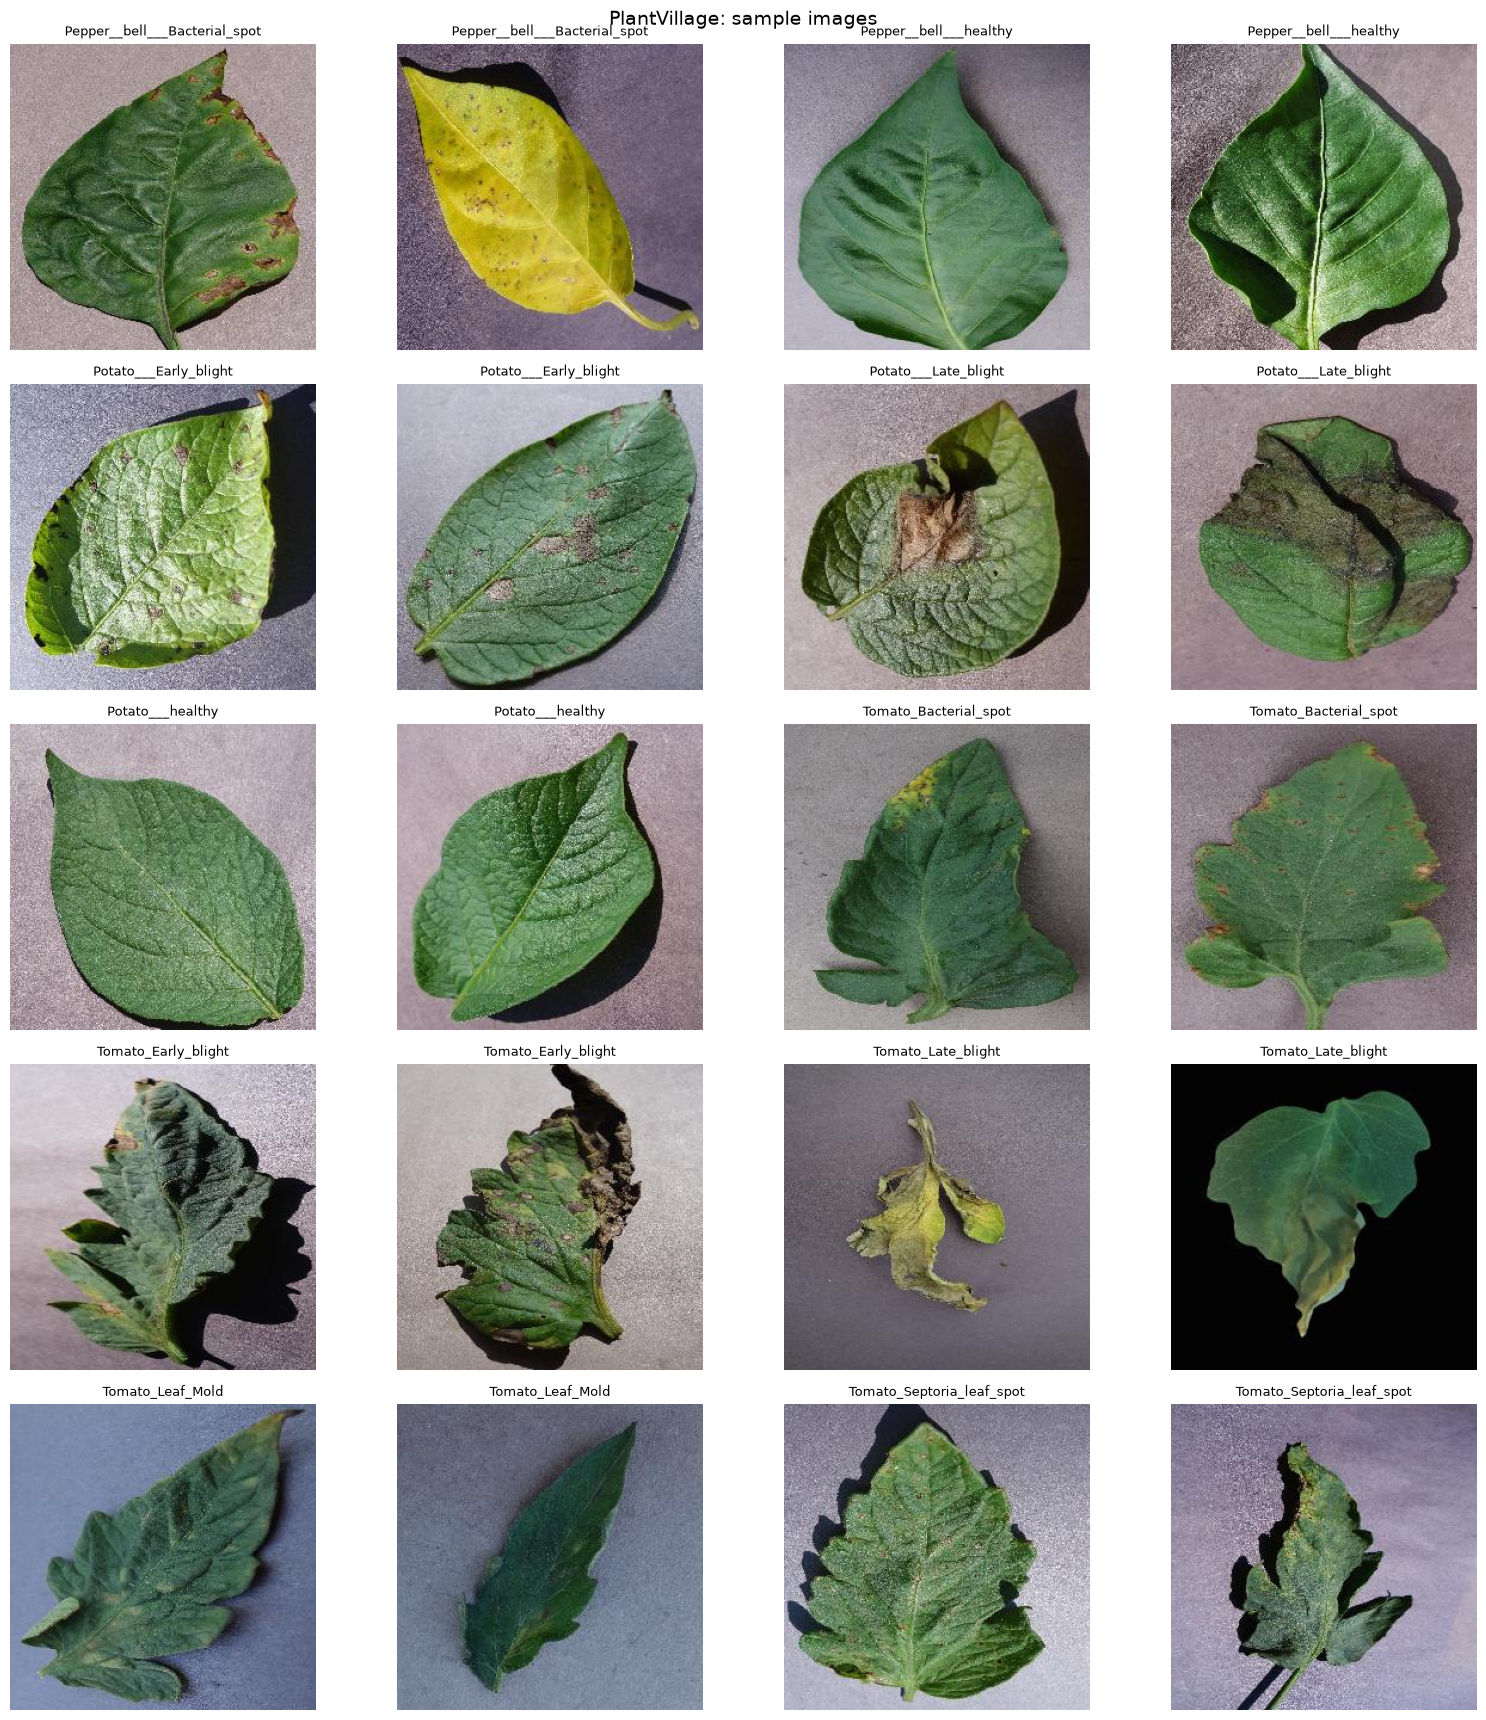

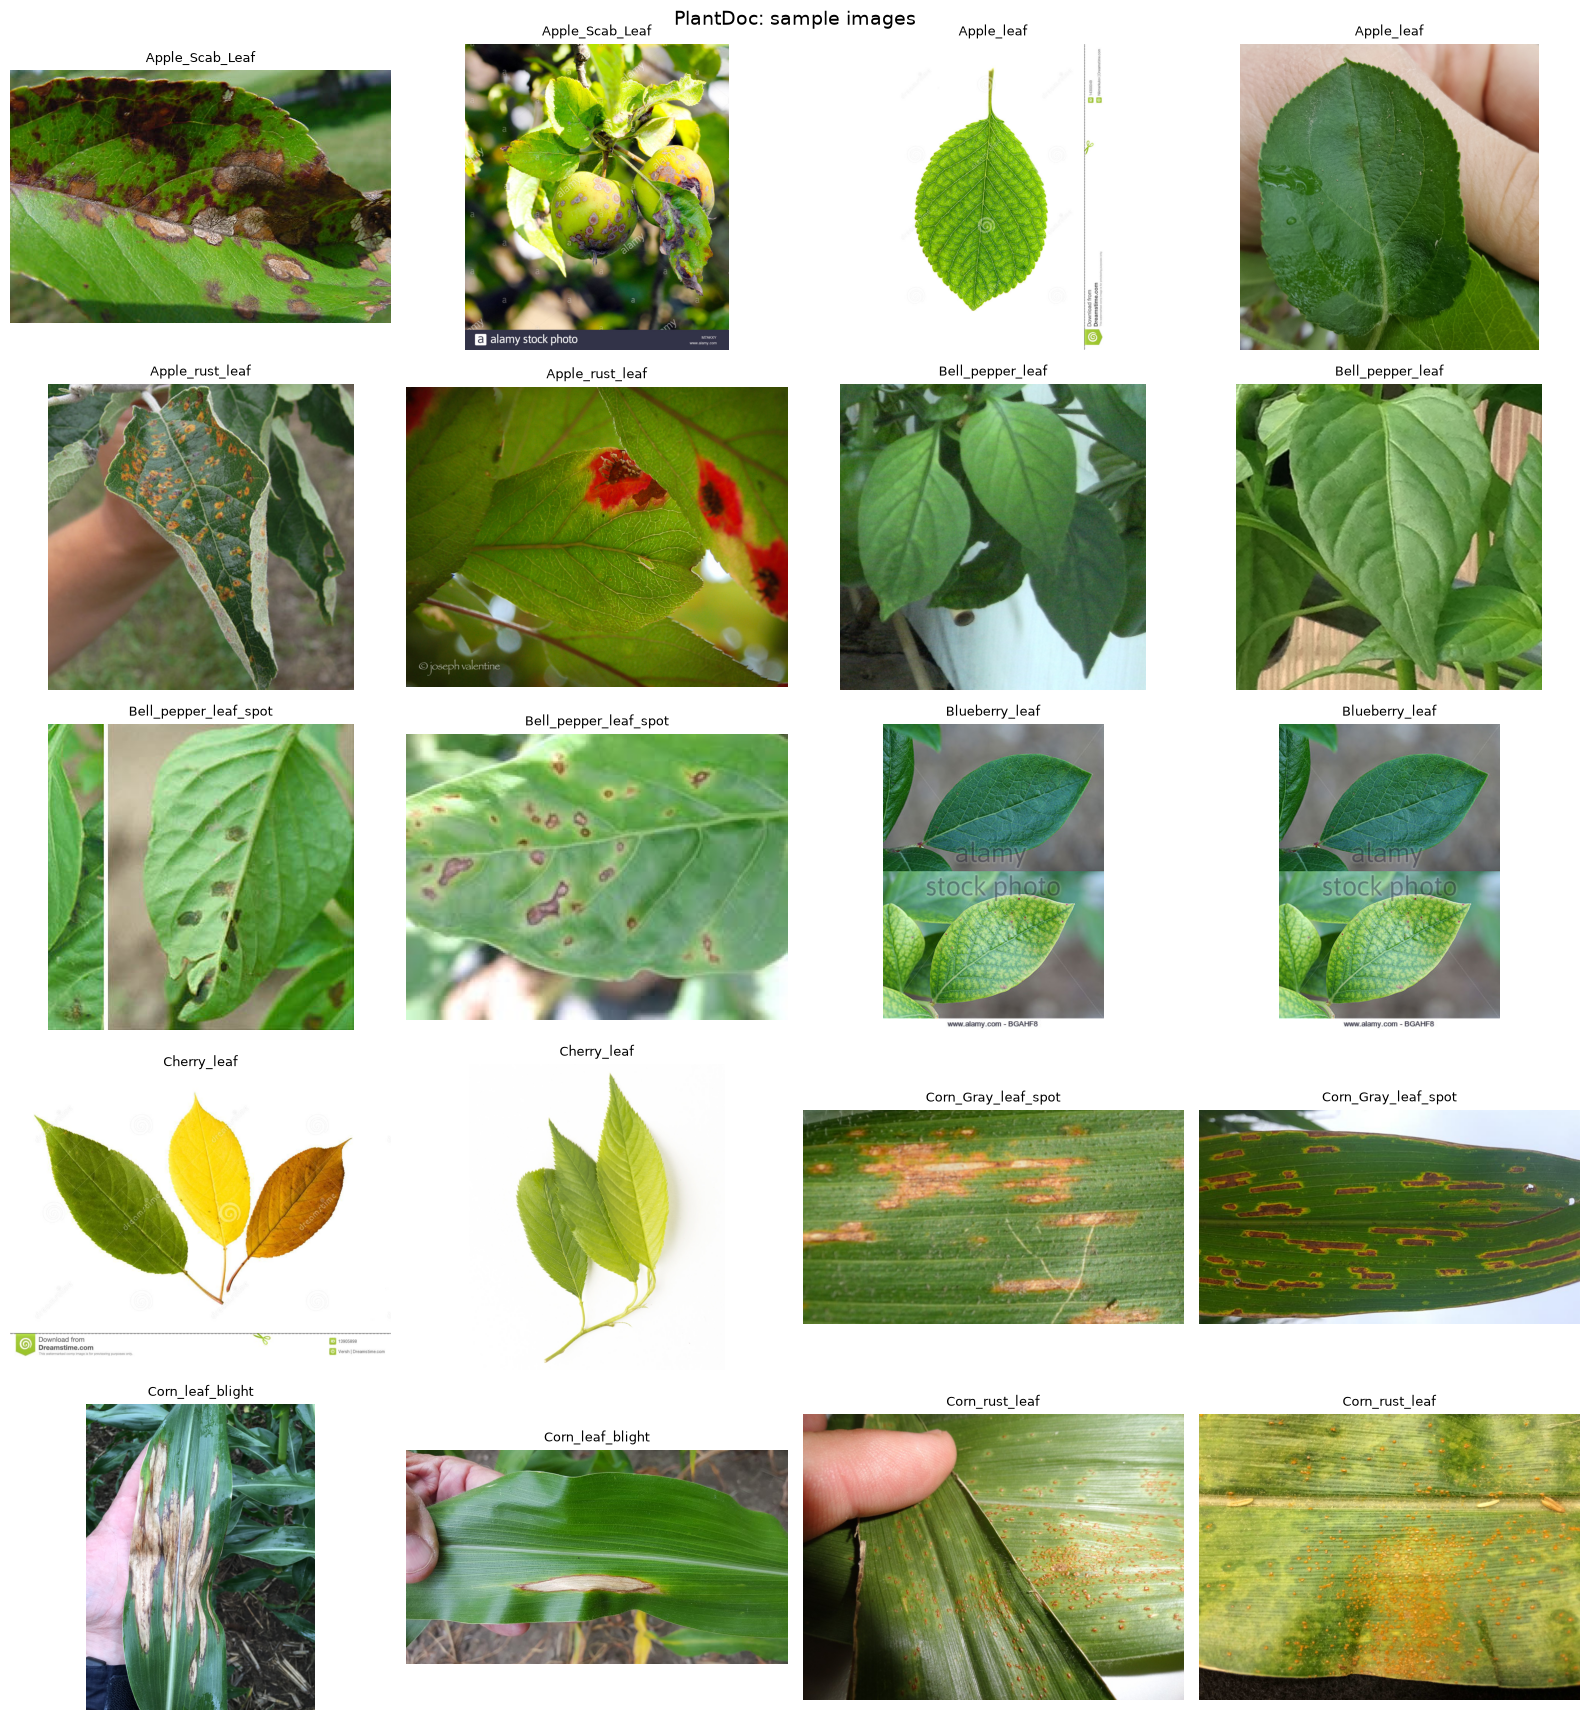

In [11]:
def show_examples(df: pd.DataFrame, dataset_name: str, n_per_class: int = 2, max_classes: int = 10):
    if df.empty:
        print(f"No {dataset_name} images to display.")
        return
    labels = sorted(df["folder_label"].unique())[:max_classes]
    selected = []
    for label in labels:
        group = df[df["folder_label"] == label]
        selected.extend(group.sample(n=min(n_per_class, len(group)), random_state=RANDOM_SEED).to_dict("records"))
    if not selected:
        return
    cols = 4
    rows = int(np.ceil(len(selected) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, record in zip(axes, selected):
        try:
            with Image.open(record["path"]) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(record["folder_label"], fontsize=9)
        except Exception:
            ax.set_title("Could not open image")
        ax.axis("off")
    for ax in axes[len(selected):]:
        ax.axis("off")
    fig.suptitle(f"{dataset_name}: sample images", fontsize=14)
    plt.tight_layout()
    plt.show()

show_examples(pv_df, "PlantVillage", n_per_class=2, max_classes=10)
show_examples(pd_df, "PlantDoc", n_per_class=2, max_classes=10)

### 8. Resolve the shared 9-class mapping against the downloaded folders

In [12]:
def normalize_label(value: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def find_alias(actual_labels, aliases):
    lookup = {normalize_label(label): label for label in actual_labels}
    for alias in aliases:
        found = lookup.get(normalize_label(alias))
        if found is not None:
            return found
    return ""

pv_labels = sorted(pv_df["folder_label"].unique()) if not pv_df.empty else []
pd_labels = sorted(pd_df["folder_label"].unique()) if not pd_df.empty else []

mapping_rows = []
for canonical, sources in CLASS_MAPPING.items():
    pv_match = find_alias(pv_labels, sources["plantvillage"])
    pd_match = find_alias(pd_labels, sources["plantdoc"])
    mapping_rows.append({
        "canonical_class": canonical,
        "plantvillage_expected_aliases": " | ".join(sources["plantvillage"]),
        "plantvillage_actual_folder": pv_match,
        "plantvillage_match": bool(pv_match),
        "plantdoc_expected_aliases": " | ".join(sources["plantdoc"]),
        "plantdoc_actual_folder": pd_match,
        "plantdoc_match": bool(pd_match),
    })

mapping_check_df = pd.DataFrame(mapping_rows)
display(mapping_check_df)
mapping_check_df.to_csv(PROCESSED_DIR / "class_mapping_check.csv", index=False)
print("Saved:", PROCESSED_DIR / "class_mapping_check.csv")
print("\nAny False value means you must verify/edit the aliases or class selection before final reporting.")

,canonical_class,plantvillage_expected_aliases,plantvillage_actual_folder,plantvillage_match,plantdoc_expected_aliases,plantdoc_actual_folder,plantdoc_match
0,Potato - early blight,Potato___Early_blight,Potato___Early_blight,True,Potato leaf early blight,Potato_leaf_early_blight,True
1,Potato - late blight,Potato___Late_blight,Potato___Late_blight,True,Potato leaf late blight,Potato_leaf_late_blight,True
2,Tomato - bacterial spot,Tomato___Bacterial_spot,Tomato_Bacterial_spot,True,Tomato leaf bacterial spot | Tomato bacterial spot leaf,Tomato_leaf_bacterial_spot,True
3,Tomato - early blight,Tomato___Early_blight,Tomato_Early_blight,True,Tomato Early blight leaf | Tomato early blight leaf,Tomato_Early_blight_leaf,True
4,Tomato - late blight,Tomato___Late_blight,Tomato_Late_blight,True,Tomato leaf late blight | Tomato late blight leaf,Tomato_leaf_late_blight,True
5,Tomato - leaf mold,Tomato___Leaf_Mold,Tomato_Leaf_Mold,True,Tomato mold leaf | Tomato leaf mold,Tomato_mold_leaf,True
6,Tomato - septoria leaf spot,Tomato___Septoria_leaf_spot,Tomato_Septoria_leaf_spot,True,Tomato Septoria leaf spot | Tomato leaf septoria spot,Tomato_Septoria_leaf_spot,True
7,Tomato - spider mites,Tomato___Spider_mites Two-spotted_spider_mite,Tomato_Spider_mites_Two_spotted_spider_mite,True,Tomato two spotted spider mites leaf | Tomato spider mites leaf,Tomato_two_spotted_spider_mites_leaf,True
8,Tomato - healthy,Tomato___healthy,Tomato_healthy,True,Tomato leaf | Tomato healthy | Tomato healthy leaf,Tomato_leaf,True


Saved: C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\processed\class_mapping_check.csv

Any False value means you must verify/edit the aliases or class selection before final reporting.


### 9. PlantDoc label review and cleaning log

In [13]:
PLANTDOC_REVIEW_CSV = PROCESSED_DIR / "plantdoc_review.csv"

review_columns = ["relative_path", "original_label", "decision", "final_label", "reason", "reviewer", "review_date"]

if not pd_df.empty:
    current_template = pd_df[["relative_path", "folder_label"]].rename(columns={"folder_label": "original_label"}).copy()
    current_template["decision"] = ""
    current_template["final_label"] = ""
    current_template["reason"] = ""
    current_template["reviewer"] = ""
    current_template["review_date"] = ""

    if PLANTDOC_REVIEW_CSV.exists():
        old_review = pd.read_csv(PLANTDOC_REVIEW_CSV, dtype=str).fillna("")
        old_review = old_review.drop_duplicates(subset=["relative_path"], keep="last")
        merged = current_template.drop(columns=["decision", "final_label", "reason", "reviewer", "review_date"]).merge(
            old_review[review_columns], on=["relative_path", "original_label"], how="left", suffixes=("", "_old")
        )
        for column in ["decision", "final_label", "reason", "reviewer", "review_date"]:
            if f"{column}_old" in merged:
                merged[column] = merged[f"{column}_old"].fillna("")
                merged = merged.drop(columns=[f"{column}_old"])
        review_df = merged[review_columns]
    else:
        review_df = current_template[review_columns]

    review_df.to_csv(PLANTDOC_REVIEW_CSV, index=False)
    print("Review file ready:", PLANTDOC_REVIEW_CSV)
    print("Rows:", len(review_df))
    print("Edit this CSV, save it, and rerun the notebook to calculate approved counts.")
    display(review_df.head(10))
else:
    review_df = pd.DataFrame(columns=review_columns)
    print("PlantDoc review file not created because no PlantDoc images were found.")

Review file ready: C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\processed\plantdoc_review.csv
Rows: 2922
Edit this CSV, save it, and rerun the notebook to calculate approved counts.


,relative_path,original_label,decision,final_label,reason,reviewer,review_date
0,test/Apple_leaf/test_Apple leaf_1.jpg,Apple_leaf,,,,,
1,test/Apple_leaf/test_Apple leaf_2.jpg,Apple_leaf,,,,,
2,test/Apple_leaf/test_Apple leaf_3.jpg,Apple_leaf,,,,,
3,test/Apple_leaf/test_Apple leaf_4.jpg,Apple_leaf,,,,,
4,test/Apple_leaf/test_Apple leaf_5.jpg,Apple_leaf,,,,,
5,test/Apple_leaf/test_Apple leaf_6.jpg,Apple_leaf,,,,,
6,test/Apple_leaf/test_Apple leaf_7.jpg,Apple_leaf,,,,,
7,test/Apple_leaf/test_Apple leaf_8.jpg,Apple_leaf,,,,,
8,test/Apple_leaf/test_Apple leaf_9.jpg,Apple_leaf,,,,,
9,test/Apple_rust_leaf/test_Apple rust leaf_1.jpg,Apple_rust_leaf,,,,,


### 10. PlantVillage duplicate review

In [14]:
def sha256_file(path_string: str, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with open(path_string, "rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

pv_hash_records = []
for row in tqdm(pv_df.itertuples(index=False), total=len(pv_df), desc="SHA-256 PlantVillage"):
    try:
        pv_hash_records.append({
            "relative_path": row.relative_path,
            "folder_label": row.folder_label,
            "sha256": sha256_file(row.path),
        })
    except Exception as exc:
        pv_hash_records.append({
            "relative_path": row.relative_path,
            "folder_label": row.folder_label,
            "sha256": "",
            "error": str(exc)[:200],
        })

pv_hash_df = pd.DataFrame(pv_hash_records)
pv_hash_df.to_csv(PROCESSED_DIR / "plantvillage_sha256.csv", index=False)

exact_pairs = []
valid_hashes = pv_hash_df[pv_hash_df["sha256"].astype(bool)]
for checksum, group in valid_hashes.groupby("sha256"):
    paths = group["relative_path"].tolist()
    if len(paths) > 1:
        for i in range(len(paths)):
            for j in range(i + 1, len(paths)):
                exact_pairs.append({
                    "pair_type": "exact_sha256",
                    "relative_path_1": paths[i],
                    "relative_path_2": paths[j],
                    "distance": 0,
                })

exact_duplicates_df = pd.DataFrame(exact_pairs, columns=["pair_type", "relative_path_1", "relative_path_2", "distance"])
exact_duplicates_df.to_csv(PROCESSED_DIR / "plantvillage_exact_duplicate_pairs.csv", index=False)
print("Exact duplicate pairs:", len(exact_duplicates_df))
print("Saved SHA-256 hashes and exact duplicate pairs.")

SHA-256 PlantVillage:   0%|          | 0/20638 [00:00<?, ?it/s]

Exact duplicate pairs: 14
Saved SHA-256 hashes and exact duplicate pairs.


In [15]:
# Simple BK-tree for approximate nearest-neighbour lookup using Hamming distance.
# It avoids comparing every pair of hashes with every other pair.
class BKTree:
    def __init__(self):
        self.root = None

    @staticmethod
    def distance(a: int, b: int) -> int:
        return (a ^ b).bit_count()

    def add(self, value: int, path: str):
        if self.root is None:
            self.root = {"value": value, "paths": [path], "children": {}}
            return
        node = self.root
        while True:
            dist = self.distance(value, node["value"])
            if dist == 0:
                node["paths"].append(path)
                return
            if dist not in node["children"]:
                node["children"][dist] = {"value": value, "paths": [path], "children": {}}
                return
            node = node["children"][dist]

    def search(self, value: int, max_distance: int):
        if self.root is None:
            return []
        matches = []
        stack = [self.root]
        while stack:
            node = stack.pop()
            dist = self.distance(value, node["value"])
            if dist <= max_distance:
                for path in node["paths"]:
                    matches.append((dist, path))
            lower, upper = dist - max_distance, dist + max_distance
            for edge_distance, child in node["children"].items():
                if lower <= edge_distance <= upper:
                    stack.append(child)
        return matches

pv_scan_df = pv_df.copy()
if PHASH_MAX_IMAGES is not None:
    pv_scan_df = pv_scan_df.head(PHASH_MAX_IMAGES).copy()

tree = BKTree()
near_pairs = []
failed_phashes = []
start_time = time.time()

exact_pair_set = {frozenset((item["relative_path_1"], item["relative_path_2"])) for item in exact_pairs}

for row in tqdm(pv_scan_df.itertuples(index=False), total=len(pv_scan_df), desc="pHash PlantVillage"):
    try:
        with Image.open(row.path) as image:
            phash_int = int(str(imagehash.phash(image.convert("RGB"))), 16)
        # Keep exact-byte duplicates in the exact duplicate report, not duplicated in this report.
        matches = tree.search(phash_int, PHASH_DISTANCE_THRESHOLD)
        for distance, previous_path in matches:
            pair_key = frozenset((previous_path, row.relative_path))
            if pair_key not in exact_pair_set:
                near_pairs.append({
                    "pair_type": "phash_candidate",
                    "relative_path_1": previous_path,
                    "relative_path_2": row.relative_path,
                    "distance": distance,
                })
        tree.add(phash_int, row.relative_path)
    except Exception as exc:
        failed_phashes.append({"relative_path": row.relative_path, "error": str(exc)[:250]})

near_duplicates_df = pd.DataFrame(near_pairs, columns=["pair_type", "relative_path_1", "relative_path_2", "distance"])
near_duplicates_df.to_csv(PROCESSED_DIR / "plantvillage_near_duplicate_candidates.csv", index=False)
pd.DataFrame(failed_phashes).to_csv(PROCESSED_DIR / "plantvillage_phash_errors.csv", index=False)

print("Images scanned for pHash:", len(pv_scan_df))
print("Near-duplicate candidate pairs:", len(near_duplicates_df))
print(f"Elapsed time: {(time.time() - start_time) / 60:.1f} minutes")
print("Saved:", PROCESSED_DIR / "plantvillage_near_duplicate_candidates.csv")

pHash PlantVillage:   0%|          | 0/20638 [00:00<?, ?it/s]

Images scanned for pHash: 20638
Near-duplicate candidate pairs: 52
Elapsed time: 0.6 minutes
Saved: C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\processed\plantvillage_near_duplicate_candidates.csv


In [16]:
# Review
PV_EXCLUSIONS_CSV = PROCESSED_DIR / "plantvillage_exclusions.csv"
exclusion_columns = ["relative_path", "reason", "reviewer", "review_date"]
if not PV_EXCLUSIONS_CSV.exists():
    pd.DataFrame(columns=exclusion_columns).to_csv(PV_EXCLUSIONS_CSV, index=False)

pv_exclusions_df = pd.read_csv(PV_EXCLUSIONS_CSV, dtype=str).fillna("")
print("PlantVillage exclusion log:", PV_EXCLUSIONS_CSV)
print("Confirmed exclusions recorded:", len(pv_exclusions_df))
display(pv_exclusions_df.head(10))

PlantVillage exclusion log: C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\processed\plantvillage_exclusions.csv
Confirmed exclusions recorded: 14


,relative_path,reason,reviewer,review_date
0,Tomato_healthy/a5de43e7-fc2f-4a14-a8e6-c0f2f94c84f1___GH_HL Leaf 434.JPG,Exact SHA-256 duplicate of Tomato_healthy/488feb1c-4b9f-44e7-8aa6-4103a9601f5f___GH_HL Leaf 434.JPG,Emin Hadziabdic,2026-11-15
1,Tomato_healthy/34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL Leaf 466.1.JPG,Exact SHA-256 duplicate of Tomato_healthy/068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL Leaf 466.1.JPG,Emin Hadziabdic,2026-11-15
2,Tomato_Late_blight/e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 Leaf 8999.JPG,Exact SHA-256 duplicate of Tomato_Late_blight/5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 Leaf 8999.JPG,Emin Hadziabdic,2026-11-15
3,Tomato_healthy/d2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL Leaf 220.JPG,Exact SHA-256 duplicate of Tomato_healthy/9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG,Emin Hadziabdic,2026-11-15
4,Tomato_Late_blight/bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f1b___GHLB_PS Leaf 23.7 Day 13.jpg,Exact SHA-256 duplicate of Tomato_Late_blight/48c55974-9fe9-4f4b-94f7-c8cd127d1e05___GHLB_PS Leaf 23.7 Day 13.jpg,Emin Hadziabdic,2026-11-15
5,Tomato_Late_blight/d82b634e-9a19-497b-b698-aaf100d622a1___GHLB_PS Leaf 24 Day 13.jpg,Exact SHA-256 duplicate of Tomato_Late_blight/861d8b00-57a4-46b0-b51a-09d102dbe119___GHLB_PS Leaf 24 Day 13.jpg,Emin Hadziabdic,2026-11-15
6,Tomato_Late_blight/5de6da85-f8c4-48c4-b463-3e6bd78884cc___GHLB_PS Leaf 24 Day 16.jpg,Exact SHA-256 duplicate of Tomato_Late_blight/3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg,Emin Hadziabdic,2026-11-15
7,Tomato_healthy/cfd491d6-4af5-4728-8f0e-0d330a07174a___GH_HL Leaf 482.2.JPG,Exact SHA-256 duplicate of Tomato_healthy/1af0bfe1-4bcf-4b8b-be66-5d0953eb647e___GH_HL Leaf 482.2.JPG,Emin Hadziabdic,2026-11-15
8,Tomato_healthy/e786ac89-29fe-47e3-b49e-b9a9ee7edd9d___GH_HL Leaf 342.1.JPG,Exact SHA-256 duplicate of Tomato_healthy/37aad83b-7ff8-4b35-b3ed-fb8e0f54910b___GH_HL Leaf 342.1.JPG,Emin Hadziabdic,2026-11-15
9,Tomato_Late_blight/e20107e7-137f-400e-817f-5dc4c58e5d70___GHLB2 Leaf 8677.JPG,Exact SHA-256 duplicate of Tomato_Late_blight/5688ea99-c949-41d0-bbab-9cbf0ffb8bcd___GHLB2 Leaf 8677.JPG,Emin Hadziabdic,2026-11-15


### 11. Calculate mapped class counts before and after the recorded cleaning decisions

In [17]:
# Reload review/exclusion files so edits made outside the notebook are picked up.
if PLANTDOC_REVIEW_CSV.exists():
    review_df = pd.read_csv(PLANTDOC_REVIEW_CSV, dtype=str).fillna("")
else:
    review_df = pd.DataFrame(columns=review_columns)

if PV_EXCLUSIONS_CSV.exists():
    pv_exclusions_df = pd.read_csv(PV_EXCLUSIONS_CSV, dtype=str).fillna("")
else:
    pv_exclusions_df = pd.DataFrame(columns=exclusion_columns)

excluded_pv_paths = set(pv_exclusions_df.loc[pv_exclusions_df["relative_path"].astype(bool), "relative_path"].astype(str)) if not pv_exclusions_df.empty else set()
pv_clean_df = pv_df[~pv_df["relative_path"].isin(excluded_pv_paths)].copy()

DECIDED_VALUES = {"keep", "uncertain", "remove"}

def canonicalize_plantdoc_label(label):
    """Map a PlantDoc folder label onto a canonical class. Empty string means out of scope."""
    normalized = normalize_label(label)
    for canonical_name, source_aliases in CLASS_MAPPING.items():
        if normalized == normalize_label(canonical_name):
            return canonical_name
        if any(normalized == normalize_label(alias) for alias in source_aliases["plantdoc"]):
            return canonical_name
    return ""

# The review scope is the mapped classes: the only PlantDoc images that enter the evaluation.
# Rows outside them are never scored, so they are reported separately instead of blocking the gate.
if not review_df.empty:
    review_df["decision_norm"] = review_df["decision"].astype(str).str.strip().str.lower()
    review_df["canonical_class"] = review_df["original_label"].apply(canonicalize_plantdoc_label)
    in_scope_mask = review_df["canonical_class"].ne("")
    decided_mask = review_df["decision_norm"].isin(DECIDED_VALUES)
    scoped_df = review_df[in_scope_mask]

    pd_in_scope_count = int(in_scope_mask.sum())
    pd_out_of_scope_count = int((~in_scope_mask).sum())
    pd_keep_paths = set(scoped_df.loc[scoped_df["decision_norm"] == "keep", "relative_path"].astype(str))
    pd_uncertain_count = int((scoped_df["decision_norm"] == "uncertain").sum())
    pd_remove_count = int((scoped_df["decision_norm"] == "remove").sum())
    pd_reviewed_count = int(scoped_df["decision_norm"].isin(DECIDED_VALUES).sum())
    pd_pending_count = int((~decided_mask & in_scope_mask).sum())
    pd_out_of_scope_pending = int((~decided_mask & ~in_scope_mask).sum())

    pd_review_data = pd_df.merge(
        review_df[["relative_path", "decision_norm", "final_label"]],
        on="relative_path", how="left"
    )
    pd_clean_df = pd_review_data[pd_review_data["decision_norm"] == "keep"].copy()
    pd_clean_df["effective_label"] = pd_clean_df["final_label"].where(
        pd_clean_df["final_label"].astype(str).str.strip().ne(""), pd_clean_df["folder_label"]
    )
    pd_clean_df["canonical_class"] = pd_clean_df["effective_label"].apply(canonicalize_plantdoc_label)
    pd_clean_df = pd_clean_df[pd_clean_df["canonical_class"].ne("")].copy()
else:
    pd_clean_df = pd.DataFrame(columns=list(pd_df.columns) + ["decision_norm", "final_label", "effective_label", "canonical_class"])
    pd_in_scope_count = pd_out_of_scope_count = 0
    pd_uncertain_count = pd_remove_count = pd_reviewed_count = 0
    pd_pending_count = 0
    pd_out_of_scope_pending = 0

print("PlantVillage images after recorded exclusions:", len(pv_clean_df))
print("PlantDoc review scope: the", len(CLASS_MAPPING), "mapped classes")
print("PlantDoc images in scope:", pd_in_scope_count)
print("PlantDoc reviewed in scope:", pd_reviewed_count)
print("PlantDoc reviewed as KEEP:", len(pd_clean_df))
print("PlantDoc UNCERTAIN:", pd_uncertain_count)
print("PlantDoc REMOVE:", pd_remove_count)
print("PlantDoc pending in scope:", pd_pending_count)
print("PlantDoc rows outside the mapped classes (never scored):", pd_out_of_scope_count,
      "of which undecided:", pd_out_of_scope_pending)
if pd_pending_count:
    print("IMPORTANT: PlantDoc final cleaned counts are not complete until every in-scope row is reviewed.")


PlantVillage images after recorded exclusions: 20624
PlantDoc review scope: the 9 mapped classes
PlantDoc images in scope: 990
PlantDoc reviewed in scope: 990
PlantDoc reviewed as KEEP: 986
PlantDoc UNCERTAIN: 0
PlantDoc REMOVE: 4
PlantDoc pending in scope: 0
PlantDoc rows outside the mapped classes (never scored): 1932 of which undecided: 1932


In [18]:
def actual_folder_for(canonical, dataset_key):
    aliases = CLASS_MAPPING[canonical][dataset_key]
    available = pv_labels if dataset_key == "plantvillage" else pd_labels
    return find_alias(available, aliases)

def count_folder(df, folder_name):
    if not folder_name or df.empty:
        return 0
    return int((df["folder_label"] == folder_name).sum())

final_mapping_rows = []
for canonical in CLASS_MAPPING:
    pv_folder = actual_folder_for(canonical, "plantvillage")
    pd_folder = actual_folder_for(canonical, "plantdoc")
    pv_raw = count_folder(pv_df, pv_folder)
    pv_clean = count_folder(pv_clean_df, pv_folder)
    pd_raw = count_folder(pd_df, pd_folder)
    pd_keep = int((pd_clean_df["canonical_class"] == canonical).sum()) if "canonical_class" in pd_clean_df.columns else 0
    final_mapping_rows.append({
        "canonical_class": canonical,
        "plantvillage_folder": pv_folder,
        "plantvillage_before_cleaning": pv_raw,
        "plantvillage_after_recorded_exclusions": pv_clean,
        "plantdoc_folder": pd_folder,
        "plantdoc_before_review": pd_raw,
        "plantdoc_reviewed_keep": pd_keep if pd_pending_count == 0 else np.nan,
        "plantdoc_mapping_found": bool(pd_folder),
        "plantvillage_mapping_found": bool(pv_folder),
    })

final_mapping_df = pd.DataFrame(final_mapping_rows)
display(final_mapping_df)
final_mapping_df.to_csv(PROCESSED_DIR / "week7_class_mapping_counts.csv", index=False)
print("Saved:", PROCESSED_DIR / "week7_class_mapping_counts.csv")

if not mapping_check_df[["plantvillage_match", "plantdoc_match"]].all().all():
    print("WARNING: One or more class aliases did not match actual folders. Fix CLASS_MAPPING and rerun.")
if pd_pending_count:
    print("WARNING: PlantDoc still has pending in-scope review rows; its after-cleaning counts are intentionally blank.")
else:
    print(f"PlantDoc after-cleaning counts published for the {len(CLASS_MAPPING)} mapped classes; "
          f"{pd_out_of_scope_count} rows outside the scope are excluded from the evaluation.")

,canonical_class,plantvillage_folder,plantvillage_before_cleaning,plantvillage_after_recorded_exclusions,plantdoc_folder,plantdoc_before_review,plantdoc_reviewed_keep,plantdoc_mapping_found,plantvillage_mapping_found
0,Potato - early blight,Potato___Early_blight,1000,1000,Potato_leaf_early_blight,171,171,True,True
1,Potato - late blight,Potato___Late_blight,1000,1000,Potato_leaf_late_blight,208,208,True,True
2,Tomato - bacterial spot,Tomato_Bacterial_spot,2127,2127,Tomato_leaf_bacterial_spot,110,107,True,True
3,Tomato - early blight,Tomato_Early_blight,1000,1000,Tomato_Early_blight_leaf,88,88,True,True
4,Tomato - late blight,Tomato_Late_blight,1909,1901,Tomato_leaf_late_blight,111,111,True,True
5,Tomato - leaf mold,Tomato_Leaf_Mold,952,952,Tomato_mold_leaf,91,90,True,True
6,Tomato - septoria leaf spot,Tomato_Septoria_leaf_spot,1771,1771,Tomato_Septoria_leaf_spot,157,157,True,True
7,Tomato - spider mites,Tomato_Spider_mites_Two_spotted_spider_mite,1676,1676,Tomato_two_spotted_spider_mites_leaf,2,2,True,True
8,Tomato - healthy,Tomato_healthy,1591,1585,Tomato_leaf,52,52,True,True


Saved: C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\processed\week7_class_mapping_counts.csv
PlantDoc after-cleaning counts published for the 9 mapped classes; 1932 rows outside the scope are excluded from the evaluation.


### 12. Export a compact audit summary

In [19]:
audit_summary = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "plantvillage_root": str(PLANTVILLAGE_DIR),
    "plantdoc_root": str(PLANTDOC_DIR),
    "plantvillage_images_found": int(len(pv_df)),
    "plantdoc_images_found": int(len(pd_df)),
    "plantvillage_images_after_recorded_exclusions": int(len(pv_clean_df)),
    "plantdoc_review_scope": "mapped classes only",
    "plantdoc_images_in_scope": int(pd_in_scope_count),
    "plantdoc_reviewed_in_scope": int(pd_reviewed_count),
    "plantdoc_keep_reviewed": int(len(pd_clean_df)),
    "plantdoc_uncertain": int(pd_uncertain_count),
    "plantdoc_remove": int(pd_remove_count),
    "plantdoc_pending_review": int(pd_pending_count),
    "plantdoc_rows_outside_scope": int(pd_out_of_scope_count),
    "plantdoc_out_of_scope_pending": int(pd_out_of_scope_pending),
    "plantvillage_exact_duplicate_pairs": int(len(exact_duplicates_df)),
    "plantvillage_near_duplicate_candidate_pairs": int(len(near_duplicates_df)),
    "phash_distance_threshold": int(PHASH_DISTANCE_THRESHOLD),
    "phash_images_scanned": int(len(pv_scan_df)),
    "class_mapping_matches_all": bool(mapping_check_df[["plantvillage_match", "plantdoc_match"]].all().all()) if not mapping_check_df.empty else False,
    "warning": "Near-duplicate pairs require human confirmation. PlantDoc counts cover the mapped classes only; images outside them are not evaluated.",
}

with open(PROCESSED_DIR / "week7_audit_summary.json", "w", encoding="utf-8") as file:
    json.dump(audit_summary, file, indent=2, ensure_ascii=False)

summary_table = pd.DataFrame([{"item": key, "value": value} for key, value in audit_summary.items()])
display(summary_table)
print("Saved:", PROCESSED_DIR / "week7_audit_summary.json")


,item,value
0,created_utc,2026-11-15T22:02:28.866038+00:00
1,plantvillage_root,C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\raw\plantvillage\PlantVillage
2,plantdoc_root,C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\raw\plantdoc
3,plantvillage_images_found,20638
4,plantdoc_images_found,2922
5,plantvillage_images_after_recorded_exclusions,20624
6,plantdoc_review_scope,mapped classes only
7,plantdoc_images_in_scope,990
8,plantdoc_reviewed_in_scope,990
9,plantdoc_keep_reviewed,986


Saved: C:\Users\eminha\Documents\Projects\AAI\LeafShift\data\processed\week7_audit_summary.json


### 13. Files created by this notebook

| File | Purpose |
|---|---|
| `raw_class_counts.csv` | Raw number of images in each folder class. |
| `image_quality_report.csv` | Image readability, dimensions, and file-level errors. |
| `class_mapping_check.csv` | Shows whether proposed aliases match actual dataset folders. |
| `plantdoc_review.csv` | Human review and cleaning decisions for PlantDoc. |
| `plantvillage_sha256.csv` | SHA-256 hashes for PlantVillage files. |
| `plantvillage_exact_duplicate_pairs.csv` | Exact duplicate pairs. |
| `plantvillage_near_duplicate_candidates.csv` | pHash near-duplicate candidates requiring review. |
| `plantvillage_exclusions.csv` | Human-confirmed PlantVillage exclusions. |
| `week7_class_mapping_counts.csv` | Proposed mapping and counts before/after recorded cleaning. |
| `week7_audit_summary.json` | Compact audit summary for the report. |